# MediaPipe baseline — 3DPW (20 frames)

This notebook runs MediaPipe on 20 images from `downtown_arguing_00` and produces **preliminary PA-MPJPE diagnostics**, a CSV, and a graph. It uses the 10 selected joints (shoulders, elbows, wrists, knees, ankles). It **does not report a verified MPJPE benchmark**: MediaPipe and 3DPW 3D coordinate systems and joint definitions still require validation. The fixed crop and actor match are specific to this sequence.

**Run all cells in order** after a Colab reset. Keep the licensed 3DPW data in your private Drive, not public GitHub.

In [1]:
# Install MediaPipe (needed again after a Colab runtime reset)
%pip -q install mediapipe

In [2]:
# Connect to the private dataset in Google Drive
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import pickle
import numpy as np
import cv2
import matplotlib.pyplot as plt
import mediapipe as mp
import pandas as pd
import requests
import sys

root = Path('/content/drive/MyDrive/3D Pose Project/3DPW')
image_folder = root / 'sample_images'
sequence_file = root / 'sequenceFiles/test/downtown_arguing_00.pkl'

if not sequence_file.exists():
    raise FileNotFoundError(f'Missing 3DPW sequence: {sequence_file}')

with open(sequence_file, 'rb') as f:
    data = pickle.load(f, encoding='latin1')

print('Sequence:', data['sequence'])
print('People:', len(data['jointPositions']))

Mounted at /content/drive
Sequence: downtown_arguing_00
People: 2


In [3]:
# Download the pose model and the team's metrics.py when needed
model_path = Path('/content/pose_landmarker.task')
model_url = 'https://storage.googleapis.com/mediapipe-models/pose_landmarker/pose_landmarker_lite/float16/1/pose_landmarker_lite.task'
if not model_path.exists() or model_path.stat().st_size < 1_000_000:
    response = requests.get(model_url, timeout=120)
    response.raise_for_status()
    model_path.write_bytes(response.content)

metrics_url = 'https://raw.githubusercontent.com/elifdilabayrak/Computer-Vision-Applied-Project/patch-1/3d-pose-diff-render/src/metrics.py'
response = requests.get(metrics_url, timeout=60)
response.raise_for_status()
metrics_text = response.text.lstrip()  # Handle earlier leading whitespace in the file
compile(metrics_text, 'metrics.py', 'exec')
Path('/content/metrics.py').write_text(metrics_text)
sys.path.insert(0, '/content')
sys.modules.pop('metrics', None)
from metrics import mpjpe, pa_mpjpe

print('Pose model and evaluation functions ready')

Pose model and evaluation functions ready


In [4]:
# Select matching joints in the same order
mp_joint_ids = [11, 12, 13, 14, 15, 16, 25, 26, 27, 28]
smpl_joint_ids = [16, 17, 18, 19, 20, 21, 4, 5, 7, 8]

# Check which person is on the left
for person_id, poses in enumerate(data['poses2d']):
    joints_2d = np.asarray(poses[0])  # (3, 18): x, y, confidence
    valid = joints_2d[2] > 0
    mean_x = np.mean(joints_2d[0, valid]) if np.any(valid) else float('nan')
    print(f'Person {person_id}: mean x = {mean_x:.1f}')

# Person 0 is the left person in this sequence (checked from the image).
person_id = 0
crop_y1, crop_y2, crop_x1, crop_x2 = 80, 1020, 780, 1100

Person 0: mean x = 965.5
Person 1: mean x = 1273.0


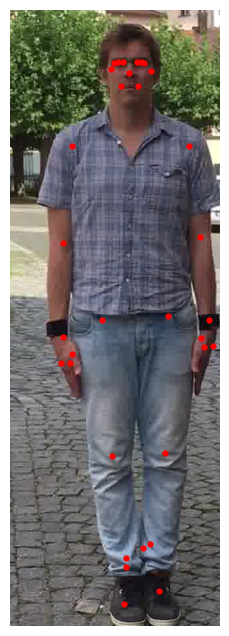

Landmarks detected: 33
World landmarks detected: 33


In [5]:
#Show the detected joints on the first image
image_path = image_folder / 'image_00000.jpg'
image = cv2.imread(str(image_path))
if image is None:
    raise FileNotFoundError(f'Could not read {image_path}')
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
left_person = image_rgb[crop_y1:crop_y2, crop_x1:crop_x2]

options = mp.tasks.vision.PoseLandmarkerOptions(
    base_options=mp.tasks.BaseOptions(model_asset_path=str(model_path)),
    running_mode=mp.tasks.vision.RunningMode.IMAGE,
    num_poses=1
)

with mp.tasks.vision.PoseLandmarker.create_from_options(options) as detector:
    mp_image = mp.Image(image_format=mp.ImageFormat.SRGB,
                        data=np.ascontiguousarray(left_person))
    detection = detector.detect(mp_image)

if not detection.pose_landmarks:
    raise RuntimeError('No person detected in frame 0')

landmarks = detection.pose_landmarks[0]
plt.figure(figsize=(5, 8))
plt.imshow(left_person)
plt.scatter([p.x * left_person.shape[1] for p in landmarks],
            [p.y * left_person.shape[0] for p in landmarks], s=12, c='red')
plt.axis('off')
plt.show()
print('Landmarks detected:', len(landmarks))
print('World landmarks detected:', len(detection.pose_world_landmarks[0]))

In [6]:
# Test MediaPipe on 20 images
errors = []
successful_frames = []

with mp.tasks.vision.PoseLandmarker.create_from_options(options) as detector:
    for frame in range(20):
        image_path = image_folder / f'image_{frame:05d}.jpg'
        image = cv2.imread(str(image_path))
        if image is None:
            print('Missing image:', image_path.name)
            continue

        image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        cropped = image_rgb[crop_y1:crop_y2, crop_x1:crop_x2]
        mp_image = mp.Image(image_format=mp.ImageFormat.SRGB,
                            data=np.ascontiguousarray(cropped))
        detection = detector.detect(mp_image)
        if not detection.pose_world_landmarks:
            print('No detection in frame', frame)
            continue

        landmarks = detection.pose_world_landmarks[0]
        predicted = np.array([[landmarks[i].x, landmarks[i].y, landmarks[i].z]
                              for i in mp_joint_ids])
        ground_truth = np.asarray(data['jointPositions'][person_id][frame]).reshape(24, 3)[smpl_joint_ids]
        errors.append(pa_mpjpe(predicted, ground_truth))
        successful_frames.append(frame)

print('Frames evaluated:', len(errors), '/ 20')
if not errors:
    raise RuntimeError('No valid frames evaluated')
print('Preliminary mean PA-MPJPE:', round(float(np.mean(errors)), 2), 'mm')
print('Minimum:', round(float(np.min(errors)), 2), 'mm')
print('Maximum:', round(float(np.max(errors)), 2), 'mm')

Frames evaluated: 20 / 20
Preliminary mean PA-MPJPE: 45.76 mm
Minimum: 39.46 mm
Maximum: 56.09 mm


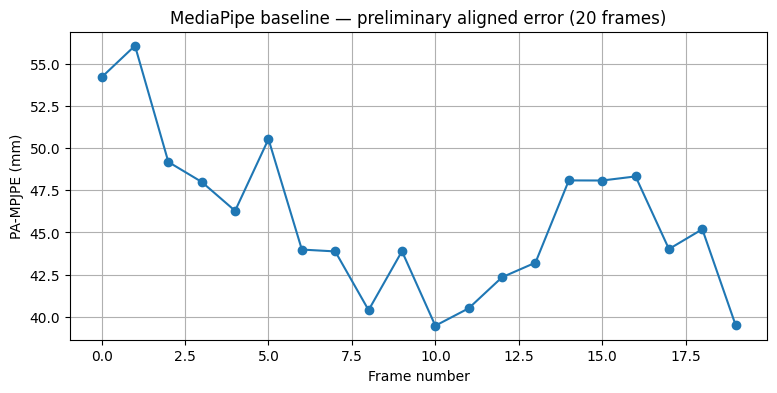

CSV saved: True
Graph saved: True
   frame  pa_mpjpe_mm
0      0    54.212107
1      1    56.086052
2      2    49.184807
3      3    47.998456
4      4    46.283358


In [7]:
# Save the preliminary results and plot to Google Drive
output_folder = root.parent
results_df = pd.DataFrame({'frame': successful_frames, 'pa_mpjpe_mm': errors})
csv_path = output_folder / 'mediapipe_baseline_results.csv'
plot_path = output_folder / 'mediapipe_baseline_plot.png'
results_df.to_csv(csv_path, index=False)

plt.figure(figsize=(9, 4))
plt.plot(results_df['frame'], results_df['pa_mpjpe_mm'], marker='o')
plt.xlabel('Frame number')
plt.ylabel('PA-MPJPE (mm)')
plt.title('MediaPipe baseline — preliminary aligned error (20 frames)')
plt.grid(True)
plt.savefig(plot_path, dpi=150, bbox_inches='tight')  # Save BEFORE showing
plt.show()

print('CSV saved:', csv_path.exists())
print('Graph saved:', plot_path.exists())
print(results_df.head())

## Important limitations before reporting final results

- This uses a **fixed crop** and assumes **3DPW Person 0 = the left person** throughout these 20 frames. Verify matching if changing sequences or frames.
- MediaPipe world landmarks are pelvis-relative estimates; 3DPW joints use SMPL definitions and another coordinate convention. **PA-MPJPE here is only a preliminary diagnostic**, not an official accuracy claim.
- **Do not calculate raw MPJPE** by directly subtracting these coordinate arrays. First establish comparable axes, scale, reference frame, and body joint definitions; decide a consistent root-alignment protocol with the team.
- For a meaningful before/after comparison, Jaylin must use **the same 10 joints, person, frames, and evaluation protocol** for the optimized pose.
- Only 20 adjacent frames from one sequence are used; these are not an independent or representative dataset-wide benchmark.